In [ ]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.metadata_visualisation import VisualisationMetadata

In [ ]:
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata_new.parquet")

# **Load Data**

In [ ]:
df_paper = pd.read_parquet("../data/paper/paper_dataset.parquet")
df_paper = df_paper[df_paper["Quinex"] == True]

📂 Loaded DataFrame from '../data/paper/paper_dataset.parquet' with 81073 rows


In [ ]:
metadata_df = pd.read_parquet("../data/quinex/df_quinex_metadata.parquet")
quinex_df = pd.read_parquet("../data/visualisation_files/df_technologies_nan.parquet")

📂 Loaded DataFrame from '../data/quinex/df_quinex_metadata.parquet' with 31636 rows
📂 Loaded DataFrame from '../data/visualisation_files/df_technologies_nan.parquet' with 3244657 rows


In [5]:
metadata_df = metadata_df.drop_duplicates(subset="DOI", keep="first")
len(metadata_df)

31636

# **Analysis Metadata**

c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:1066: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


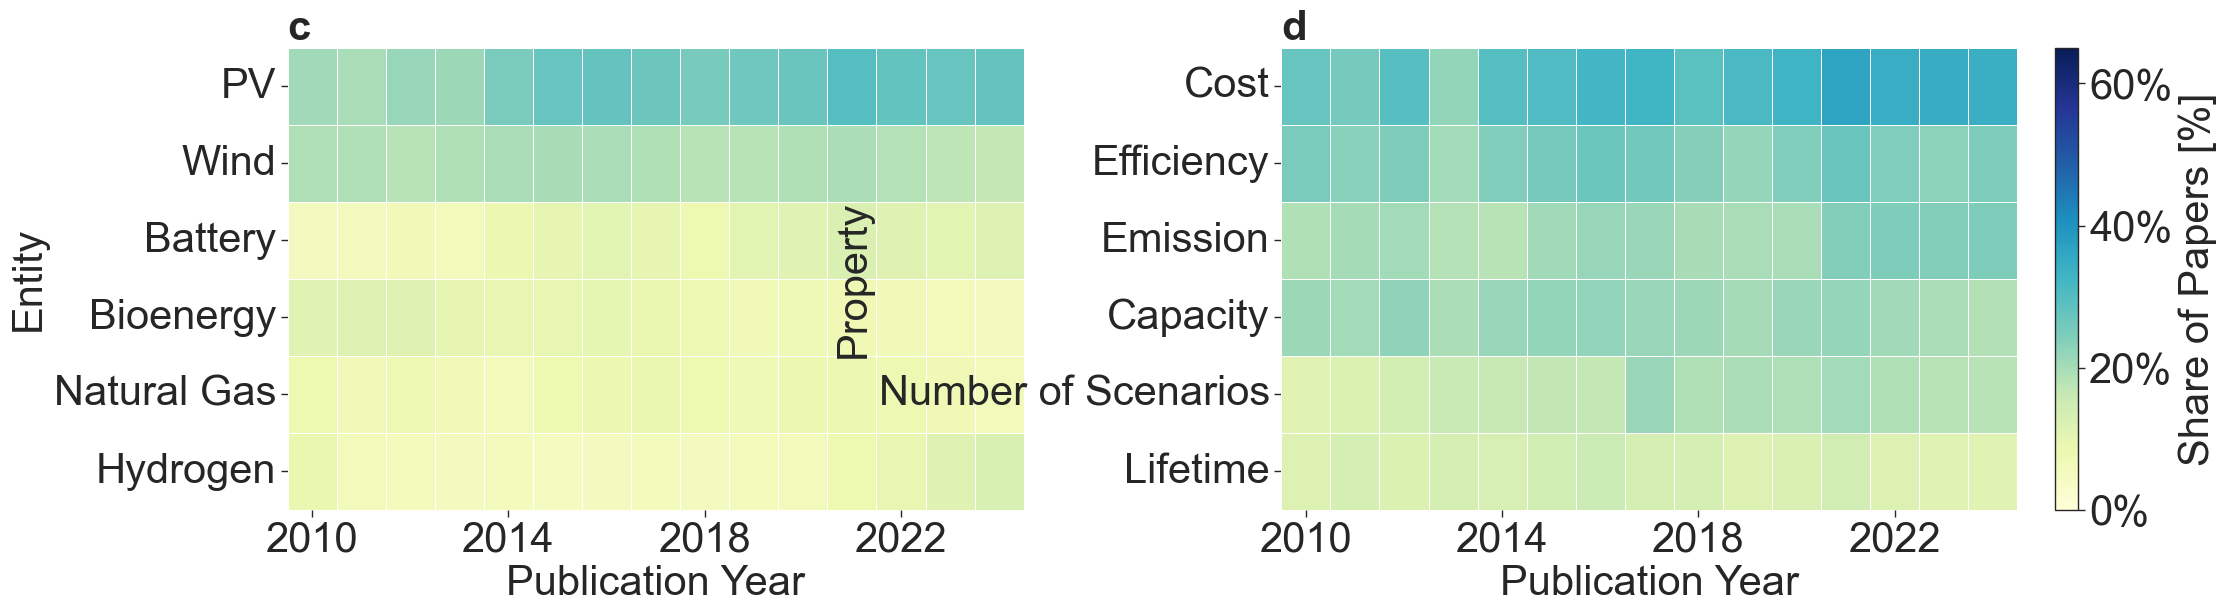

In [24]:
fig, piv_entity, piv_property = metadata.mention_trend_heatmap(
    quinex_df[quinex_df["publication_year"] < 2025], 
    "entity_base_mapping", 
    "property_base_mapping", 
    figsize=(24,6), 
    font_size=30, 
    top_n=6, 
    cmap="YlGnBu",
    color_scale_percent=(0,65)
)
fig.savefig("../data/figures/metadata/ent_prop_distribution.pdf", bbox_inches='tight')

In [ ]:
# metadata_df = metadata_df.drop(columns=["funders_x", "funders_y", "institutions_x", "institutions_y"])

KeyError: "['funders_x', 'funders_y', 'institutions_x', 'institutions_y'] not found in axis"

In [ ]:
metadata_df.columns

In [ ]:
 metadata_df = metadata.add_sjr_to_metadata(
    metadata_df,
    sjr_folder="../data/paper/impactfactor",
    source_col="source",
    year_col="publication_year",
    #source_rename_dict=source_rename_dict
)

metadata_df = metadata_df.merge(
    df_paper[['DOI', 'Source title']],
    on='DOI',
    how='left'
)

mask = metadata_df['SJR'].isna()
metadata_fallback = metadata_df.loc[mask].copy()
metadata_fallback = metadata.add_sjr_to_metadata(
    metadata_fallback,
    sjr_folder="../data/paper/impactfactor",
    source_col="Source title",
    year_col="publication_year",
)
metadata_df.loc[mask, 'SJR'] = metadata_fallback['SJR'].values

In [ ]:
len(metadata_df)

In [ ]:
metadata_df.to_parquet("../data/quinex/df_quinex_metadata.parquet")

Missing country info: 1542 papers (5.80%)
Missing SJR info: 1069 papers (4.02%)


c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:470: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)
c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:531: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  agg[plot_column] = (agg['share_sum'] / agg['norm_share_sum']).fillna(0)


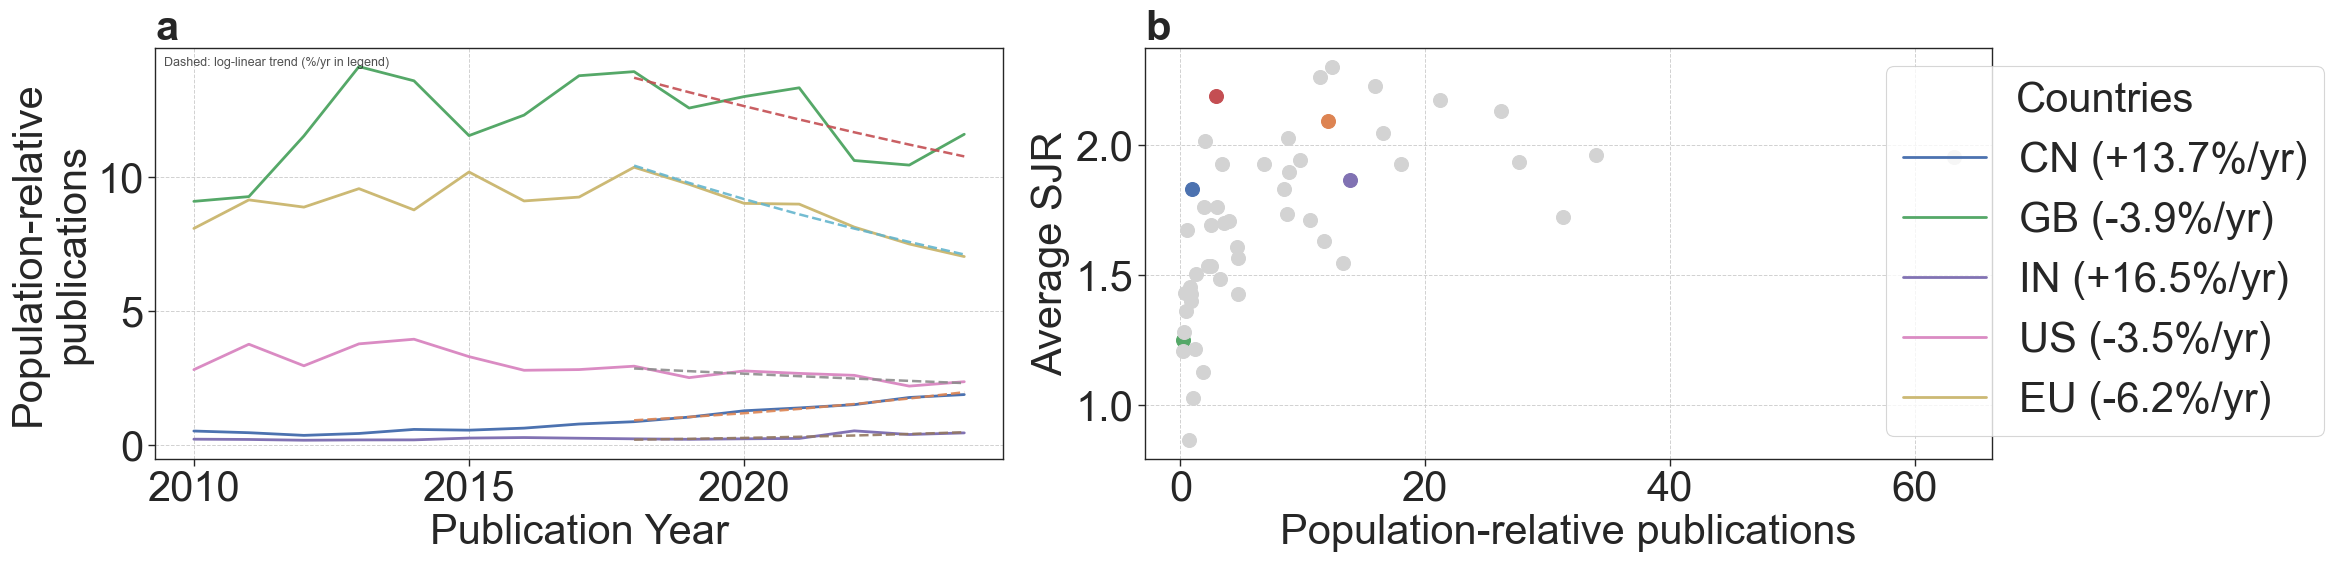

In [11]:
eu_countries = {
    "EU": ["DE", "FR", "IT", "ES", "NL", "BE", "AT", "SE", "DK", "PL", "GR", "PT", "CZ", "FI", "RO", "HU", "BG", "HR", "SI", "SK", "IE"]
}

fig, pivot_countries, avg_sjr = metadata.countries_share_and_sjr(
    metadata_df,
    top_n_line = 5, 
    top_n_scatter = 50, 
    figsize = (24, 6), 
    font_size=30, 
    legend_bbox=(0.885,0.55),
    max_year=2024,
    normalize_by_population=True,
    population_excel_path="../data/visualisation_files/country_add_info/world_population.xlsx",
    # normalize_by_gdp=True,
    # gdp_excel_path="../data/visualisation_files/world_gdp.xls",
    country_groups=eu_countries,
    add_regression_lines=True,
    regression_start_year=2018,
    regression_end_year=2024
)
#fig.savefig("../data/figures/metadata/share_top_countries.pdf", bbox_inches='tight')

### **Country Comparison**

In [8]:
# Create DataFrames for additional top research nations
def get_df_by_country(metadata_df, quinex_df, country_code):
    """Filter quinex_df for publications from a specific country."""
    pubs = metadata_df[metadata_df['countries'].apply(lambda x: country_code in x)]
    dois = pubs['DOI'].tolist()
    return quinex_df[quinex_df['DOI'].isin(dois)]

# Create EU DataFrame by aggregating EU countries
def get_df_by_countries(metadata_df, quinex_df, country_codes):
    """Filter quinex_df for publications from a list of countries."""
    pubs = metadata_df[metadata_df['countries'].apply(
        lambda x: any(code in x for code in country_codes)
    )]
    dois = pubs['DOI'].tolist()
    return quinex_df[quinex_df['DOI'].isin(dois)]


df_ch = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "CN")  # China
df_us = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "US")  # United States
df_jp = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "JP")  # Japan
df_in = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "IN")  # India
df_gb = get_df_by_country(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, "GB")  # United Kingdom

eu_codes = ["DE", "FR", "IT", "ES", "NL", "BE", "AT", "SE", "DK", "PL", "GR", "PT", "CZ", "FI", "RO", "HU", "BG", "HR", "SI", "SK", "IE"]
df_eu = get_df_by_countries(metadata_df[metadata_df["publication_year"] < 2025], quinex_df, eu_codes)

print(f"EU: {len(df_eu['DOI'].value_counts())} entries")
print(f"China: {len(df_ch['DOI'].value_counts())} entries")
print(f"USA: {len(df_us['DOI'].value_counts())} entries")
print(f"UK: {len(df_gb['DOI'].value_counts())} entries")
print(f"Japan: {len(df_jp['DOI'].value_counts())} entries")
print(f"India: {len(df_in['DOI'].value_counts())} entries")

EU: 9653 entries
China: 5591 entries
USA: 2895 entries
UK: 2596 entries
Japan: 625 entries
India: 1372 entries


c:\Gorres\Projekte\quinex_application\quinex_application\visualisation\metadata_visualisation.py:947: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.12, 1, 1])


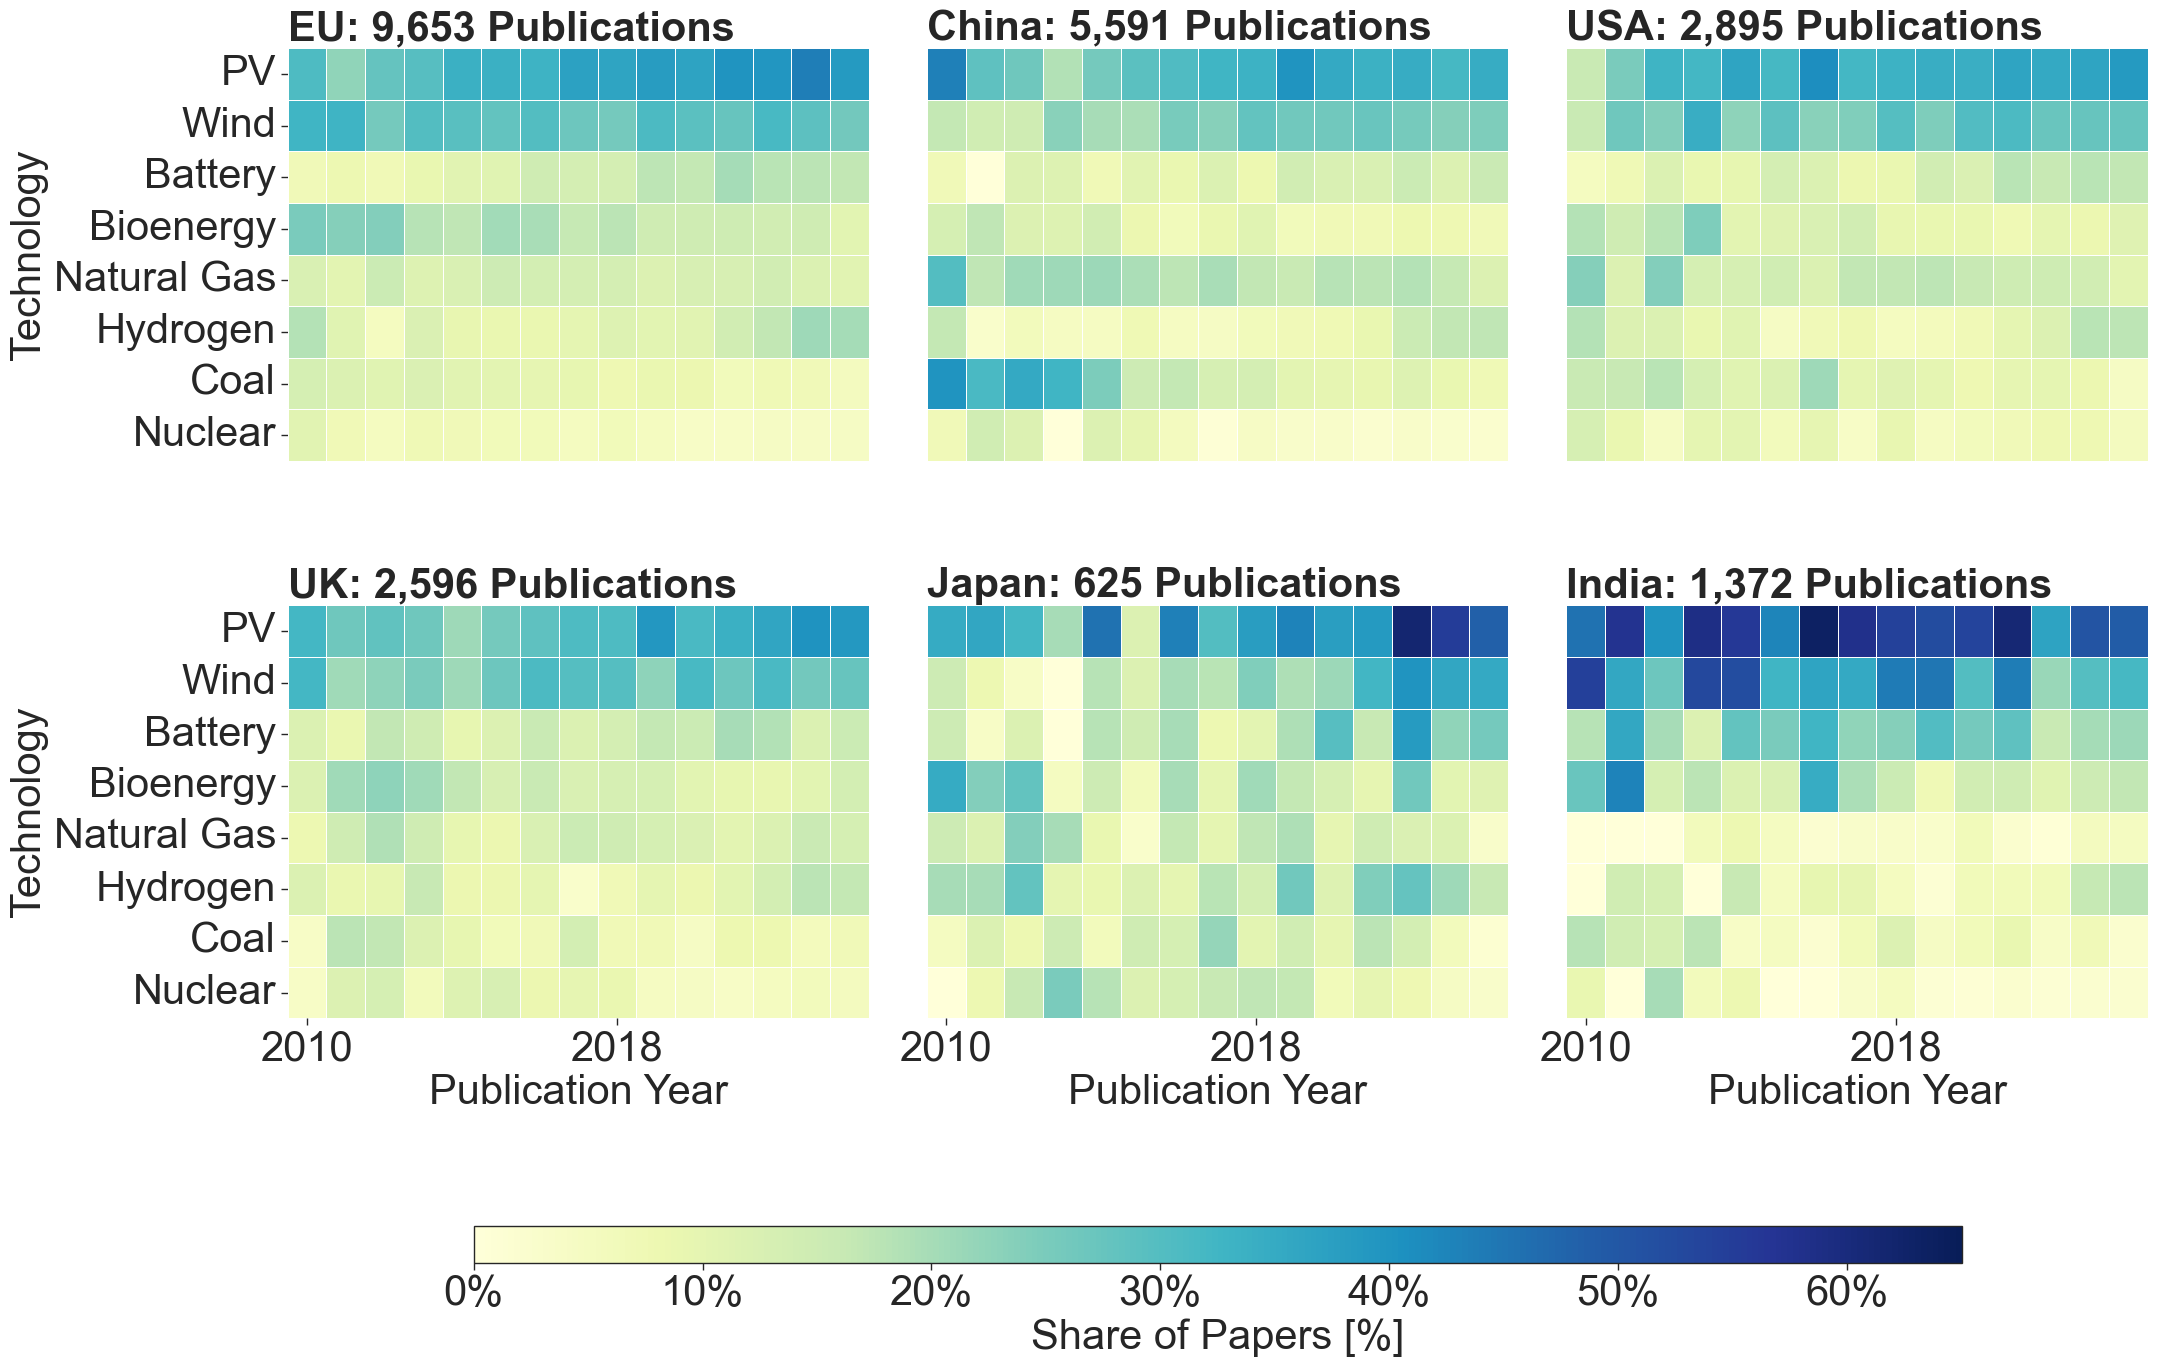

In [9]:
# 3 countries/regions: 3 columns, 1 row
fig, piv_entity = metadata.mention_trend_heatmap_multi_entities(
    dfs = [df_eu, df_ch, df_us, df_gb, df_jp, df_in],
    titles = [
        "EU: 9,653 Publications",
        "China: 5,591 Publications", 
        "USA: 2,895 Publications", 
        "UK: 2,596 Publications", 
        "Japan: 625 Publications", 
        "India: 1,372 Publications"
    ],
    entity_col = "entity_base_mapping",
    figsize=(24, 9),
    font_size=30, 
    top_n=8, 
    cmap="YlGnBu",
    n_cols=3,
    color_scale_percent=(0,65)
)
fig.savefig("../data/figures/metadata/ent_6countries.pdf", bbox_inches='tight')

In [13]:
piv_entity[1]

publication_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
entity_base_mapping,,,,,,,,,,,,,,,
PV,0.433333,0.285714,0.264706,0.186047,0.258824,0.290323,0.307087,0.326923,0.334711,0.399457,0.355072,0.336486,0.347392,0.318305,0.346680
Wind,0.166667,0.142857,0.147059,0.232558,0.200000,0.193548,0.251969,0.235577,0.280992,0.263587,0.262681,0.272973,0.254162,0.237151,0.246094
Battery,0.066667,0.000000,0.117647,0.116279,0.070588,0.107527,0.086614,0.120192,0.082645,0.141304,0.125000,0.125676,0.153163,0.119026,0.157227
Bioenergy,0.133333,0.171429,0.117647,0.116279,0.141176,0.086022,0.062992,0.086538,0.111570,0.062500,0.070652,0.068919,0.083241,0.078449,0.067383
Natural Gas,0.300000,0.171429,0.205882,0.209302,0.211765,0.193548,0.173228,0.197115,0.169421,0.157609,0.181159,0.177027,0.185350,0.164112,0.119141
Hydrogen,0.166667,0.028571,0.058824,0.046512,0.047059,0.075269,0.047244,0.043269,0.061983,0.067935,0.074275,0.089189,0.153163,0.169522,0.170898
Coal,0.400000,0.314286,0.352941,0.325581,0.247059,0.150538,0.165354,0.129808,0.136364,0.103261,0.097826,0.093243,0.114317,0.089270,0.073242
Nuclear,0.066667,0.142857,0.117647,0.000000,0.117647,0.096774,0.055118,0.009615,0.041322,0.032609,0.034420,0.021622,0.035516,0.026150,0.023438
